# Company A telecom retention proof of concept

Company A needs to identify which customers to contact before they leave when the retention team can reach only a fraction of the customer base. This notebook analyzes the supplied telecom data, trains one XGBoost classifier, and estimates what a targeted outreach pilot would need to achieve to pay for itself.

Run all cells from the notebook directory with the supplied `telecom` folder beside it. Set `TELECOM_DATA_DIR` to override the data folder. The notebook uses pandas, NumPy, Matplotlib, scikit-learn, and XGBoost.

## 1. Market context and target

In the U.S. wireless market, number portability lets customers keep their phone numbers when they switch providers. T-Mobile reported 0.93% postpaid phone churn for 2025. These sources illustrate switching and retention in a reference market. Company A's geography, customer mix, and sampling process are unconfirmed, so its live churn rate must be measured separately. [FCC number portability order](https://docs.fcc.gov/public/attachments/FCC-23-95A1.pdf) · [T-Mobile full-year 2025 results](https://www.sec.gov/Archives/edgar/data/1283699/000128369926000007/tmus12312025ex991.htm)

The supplied *Company A Dataset Overview* defines `churn` as departure 31–60 days after observation. We use it as the binary outcome and rank customers by predicted risk.

## 2. Load and validate the customer join

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

data_dir = Path(os.environ.get("TELECOM_DATA_DIR", "telecom")).expanduser()
client = pd.read_csv(data_dir / "Client.csv")
record = pd.read_csv(data_dir / "Record.csv")

id_col = "Customer_ID"
assert client[id_col].notna().all() and record[id_col].notna().all()
df = record.merge(client, on=id_col, how="inner", validate="one_to_one")
assert df["churn"].notna().all() and set(df["churn"].unique()) == {0, 1}

display(pd.DataFrame({
    "Rows": [len(client), len(record), len(df)],
    "Columns": [client.shape[1], record.shape[1], df.shape[1]],
}, index=["Client", "Record", "Matched customers"]))
print(f"Unmatched IDs: {len(client) - len(df):,} in Client and "
      f"{len(record) - len(df):,} in Record")
display(df.dtypes.value_counts().rename("Columns").to_frame())

Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories


Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories


Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories


,Rows,Columns
Client,100000,50
Record,100000,51
Matched customers,100000,100


Unmatched IDs: 0 in Client and 0 in Record


,Columns
float64,69
object,21
int64,10


## 3. Exploratory data analysis

The data-quality audit describes the full set of joined records. Target and feature comparisons below use the training partition. The holdout is reserved for model evaluation.

,Customers,Share
churn,,
Stayed,35307,0.5044
Churned,34693,0.4956


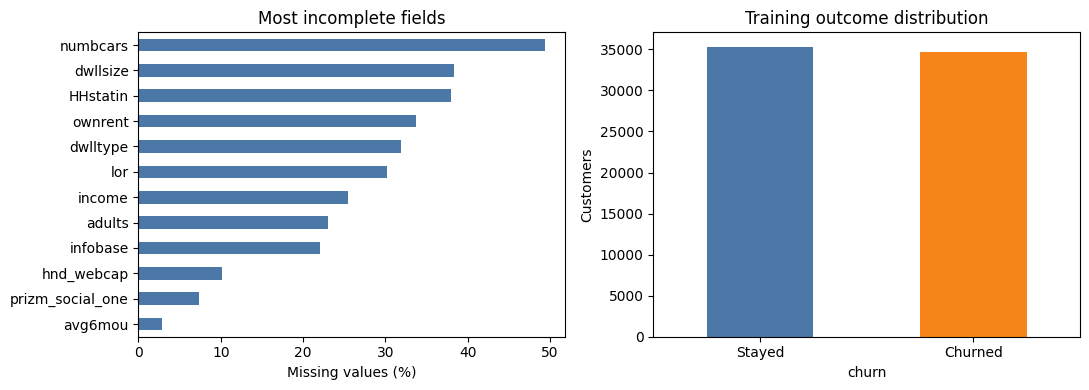

In [2]:
train, test = train_test_split(
    df, test_size=0.30, random_state=42, stratify=df["churn"]
)

missing = df.isna().mean()
top_missing = missing[missing.gt(0)].nlargest(12).mul(100)
balance = train["churn"].map({0: "Stayed", 1: "Churned"}).value_counts()
display(balance.to_frame("Customers").assign(Share=balance.div(len(train))).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
top_missing.sort_values().plot.barh(ax=axes[0], color="#4C78A8")
axes[0].set(title="Most incomplete fields", xlabel="Missing values (%)")
balance.plot.bar(ax=axes[1], rot=0, color=["#4C78A8", "#F58518"])
axes[1].set(title="Training outcome distribution", ylabel="Customers")
fig.tight_layout()
plt.show()

churn,Stayed,Churned
Handset age (days),309.00,366.00
Tenure (months),16.00,17.00
Mean monthly revenue,49.02,47.63
Change in usage (source units),-3.00,-10.50
Dropped or blocked calls,5.67,5.00
Customer care calls,0.00,0.00


,Customers,Churn_share
eqpdays,,
0 or less,129,33.3%
1–180,"12,769",41.9%
181–365,"25,477",46.8%
366–730,"24,023",54.1%
731+,"7,601",57.8%


Missing training handset age: 1


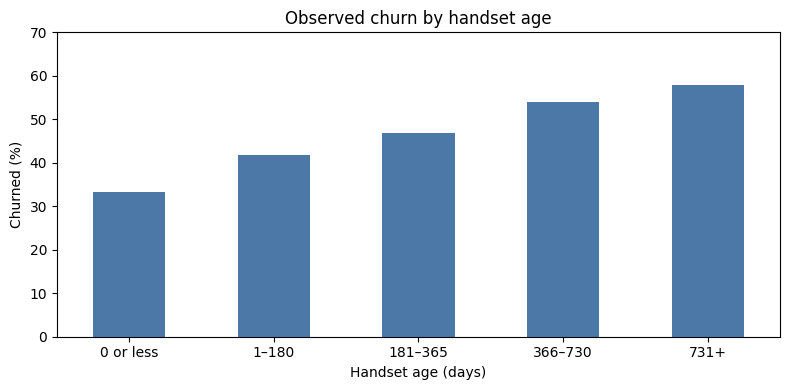

In [3]:
feature_labels = {
    "eqpdays": "Handset age (days)",
    "months": "Tenure (months)",
    "rev_Mean": "Mean monthly revenue",
    "change_mou": "Change in usage (source units)",
    "drop_blk_Mean": "Dropped or blocked calls",
    "custcare_Mean": "Customer care calls",
}
medians = (
    train.groupby("churn")[list(feature_labels)].median().T
    .rename(index=feature_labels, columns={0: "Stayed", 1: "Churned"})
)
display(medians.round(2))

handset_age = pd.cut(
    train["eqpdays"],
    bins=[-np.inf, 0, 180, 365, 730, np.inf],
    labels=["0 or less", "1–180", "181–365", "366–730", "731+"],
)
age_summary = train.groupby(handset_age, observed=True)["churn"].agg(
    Customers="size", Churn_share="mean"
)
display(age_summary.style.format({"Customers": "{:,}", "Churn_share": "{:.1%}"}))
print(f"Missing training handset age: {handset_age.isna().sum():,}")

fig, ax = plt.subplots(figsize=(8, 4))
age_summary["Churn_share"].mul(100).plot.bar(ax=ax, rot=0, color="#4C78A8")
ax.set(title="Observed churn by handset age", xlabel="Handset age (days)",
       ylabel="Churned (%)", ylim=(0, 70))
fig.tight_layout()
plt.show()

Older handsets and larger reported declines in usage distinguish the two outcomes in the training sample. Some fields, including the number of household cars, have substantial missingness. The handset comparison is observational. A device check is a plausible outreach action whose effect needs a randomized test.

## 4. Train one XGBoost classifier

Use documented numeric service, equipment, billing, and usage fields. The feature list excludes the customer ID, outcome, credit and household demographics, and lifetime totals whose collection cutoff is unclear. XGBoost can capture nonlinear relationships and route missing numeric values during training without an imputation step. Any production deployment requires verification that these inputs are available at the scoring date. The supplied data has no explicit observation date for a chronological holdout.

In [4]:
features = [
    "months", "eqpdays", "phones", "rev_Mean", "totmrc_Mean",
    "mou_Mean", "change_mou", "change_rev", "ovrmou_Mean",
    "roam_Mean", "drop_blk_Mean", "custcare_Mean", "attempt_Mean",
]
X_train, y_train = train[features], train["churn"]
X_test, y_test = test[features], test["churn"]

model = XGBClassifier(
    n_estimators=250, max_depth=4, learning_rate=0.05,
    subsample=0.85, colsample_bytree=0.9, tree_method="hist",
    eval_metric="logloss", random_state=42, n_jobs=4,
)
model.fit(X_train, y_train)
scores = pd.Series(model.predict_proba(X_test)[:, 1], index=y_test.index)

## 5. Evaluate ranking and outreach capacity

The main model metric is ROC AUC. The outreach scenario assumes capacity to contact the top 10% of ranked customers. Compare this list with random outreach at the same capacity. The confusion matrix uses that operational cutoff.

,Held-out value
ROC AUC,0.6694
Average precision,0.6622
Random ranking average precision reference (prevalence),0.4956
Accuracy at score cutoff 0.50,0.6157
Majority-class accuracy reference,0.5044
Precision at capacity,0.7703
Recall at capacity,0.1554
Lift over random outreach at capacity,1.5542


Top 3,000 contacts include 2,311 observed churners. Random outreach would include about 1,487.


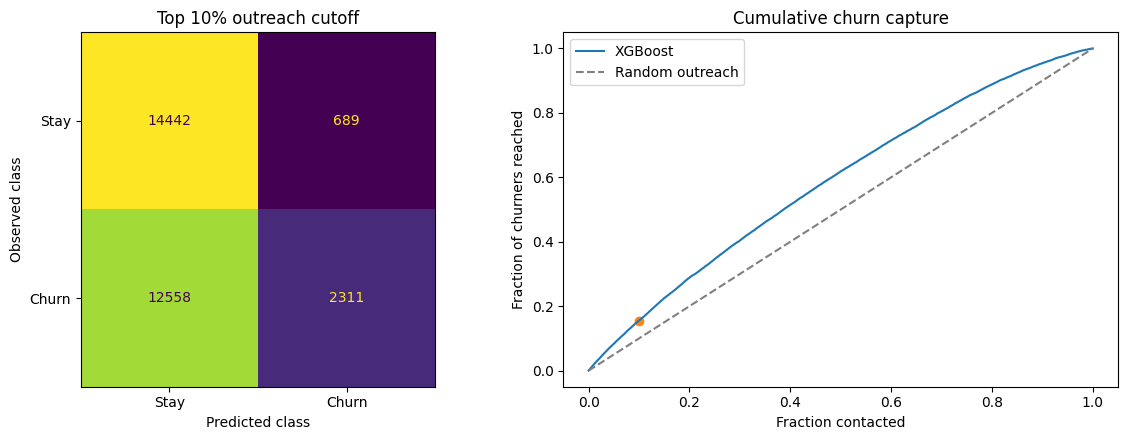

In [5]:
capacity_share = 0.10
contact_count = int(np.ceil(len(y_test) * capacity_share))
ranked = y_test.loc[scores.sort_values(ascending=False, kind="stable").index]
selected = ranked.iloc[:contact_count]
selected_churners = int(selected.sum())
test_prevalence = y_test.mean()
precision_at_capacity = selected.mean()
recall_at_capacity = selected_churners / y_test.sum()
lift = precision_at_capacity / test_prevalence
flagged = y_test.index.isin(selected.index).astype(int)

metrics = pd.Series({
    "ROC AUC": roc_auc_score(y_test, scores),
    "Average precision": average_precision_score(y_test, scores),
    "Random ranking average precision reference (prevalence)": test_prevalence,
    "Accuracy at score cutoff 0.50": accuracy_score(y_test, scores.ge(0.50)),
    "Majority-class accuracy reference": max(test_prevalence, 1 - test_prevalence),
    "Precision at capacity": precision_at_capacity,
    "Recall at capacity": recall_at_capacity,
    "Lift over random outreach at capacity": lift,
})
display(metrics.to_frame("Held-out value").round(4))
print(f"Top {contact_count:,} contacts include {selected_churners:,} observed churners. "
      f"Random outreach would include about {contact_count * test_prevalence:,.0f}.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, flagged, display_labels=["Stay", "Churn"], ax=axes[0], colorbar=False
)
axes[0].set(title="Top 10% outreach cutoff", xlabel="Predicted class", ylabel="Observed class")
x = np.arange(1, len(ranked) + 1) / len(ranked)
axes[1].plot(x, ranked.cumsum() / ranked.sum(), label="XGBoost")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Random outreach")
axes[1].scatter([contact_count / len(ranked)], [recall_at_capacity], color="#F58518")
axes[1].set(title="Cumulative churn capture", xlabel="Fraction contacted",
            ylabel="Fraction of churners reached")
axes[1].legend()
fig.tight_layout()
plt.show()

## 6. Retention pilot and quantified impact

Give the retention team a ranked list of eligible customers. Randomly assign high-risk customers to proactive outreach or usual care. Have agents offer a brief device or plan check and log the action, cost, and outcome. Compare day-31–60 churn between groups and track retained contribution margin to decide whether to expand.

The model measures who is likely to leave. The pilot measures how many departures outreach prevents. The scenario below uses assumed live prevalence and applies the observed holdout lift as an illustrative input. Lift may change on a current population. Sample churn prevalence and carrier-reported metrics use different populations and definitions. The Finance and Retention teams should replace the assumptions with live data, including any incentive and fixed implementation costs.

In [6]:
eligible_customers = 10_000
pilot_contacts = int(eligible_customers * capacity_share)
margin_per_save = 180  # Assumed incremental contribution per retained account
cost_per_contact = 2   # Assumed outreach cost per customer assigned to contact
outreach_cost = pilot_contacts * cost_per_contact

scenarios = pd.DataFrame({
    "Assumed live churn": [0.02, 0.03, 0.05],
    "Assumed fraction of would-be churners retained": [0.10, 0.20, 0.30],
}, index=["Low", "Base", "High"])
scenarios["Expected at-risk contacts"] = (
    pilot_contacts * (scenarios["Assumed live churn"] * lift).clip(upper=1)
)
scenarios["Expected saves"] = (
    scenarios["Expected at-risk contacts"]
    * scenarios["Assumed fraction of would-be churners retained"]
)
scenarios["Net contribution before fixed costs"] = (
    scenarios["Expected saves"] * margin_per_save - outreach_cost
)
scenarios["Break-even save fraction"] = (
    outreach_cost / (scenarios["Expected at-risk contacts"] * margin_per_save)
)
print(f"Scenario per {eligible_customers:,} eligible customers and {pilot_contacts:,} contacts")
print(f"Assumed contribution per save: {margin_per_save} currency units. "
      f"Outreach cost: {outreach_cost:,} currency units.")
display(scenarios.style.format({
    "Assumed live churn": "{:.0%}",
    "Assumed fraction of would-be churners retained": "{:.0%}",
    "Expected at-risk contacts": "{:.1f}",
    "Expected saves": "{:.1f}",
    "Net contribution before fixed costs": "{:,.0f}",
    "Break-even save fraction": "{:.1%}",
}))

Scenario per 10,000 eligible customers and 1,000 contacts
Assumed contribution per save: 180 currency units. Outreach cost: 2,000 currency units.


,Assumed live churn,Assumed fraction of would-be churners retained,Expected at-risk contacts,Expected saves,Net contribution before fixed costs,Break-even save fraction
Low,2%,10%,31.1,3.1,"-1,440",35.7%
Base,3%,20%,46.6,9.3,-321,23.8%
High,5%,30%,77.7,23.3,"2,196",14.3%
